<img src="MUML_header.svg" alt="Header" style="width:100%; height:auto;">

# 03_01 Linear regression

In this notebook you will build up linear regression step by step using only basic PyTorch tensors and autograd, without high-level modules or optimizers.  

The goal is to understand the mechanics of model training and explore how different choices (losses, learning rates, scaling) affect results.

## 1. Create a synthetic dataset (1D)

We’ll start with a single input feature $ x \in \mathbb{R} $ so that later we can visualize the loss surface over $(w, b)$.

To ensure reproducibility, set the NumPy (`np.random.seed`) and PyTorch (`torch.manual_seed`) seeds  as seed = 123.  
- Set the PyTorch seed with `torch.manual_seed(123)`.  

We will generate the target values `y` from a known line plus Gaussian noise:

$$
y = w_{\text{true}} \cdot x + b_{\text{true}} + \text{noise}.
$$

Use these values:

- `w_true = 2.5` (slope)  
- `b_true = -1.0` (intercept)  
- `noise_std = 0.6` (standard deviation of the Gaussian noise)  


**What to do**

1. Generate `n = 200` points for $x$, sampled uniformly from the interval $[-3, 3]$.  
2. Compute the corresponding `y` values using the formula above.  
3. Convert both `x` and `y` into **PyTorch tensors** of shape `(n, 1)` and dtype `float32`.  
4. Plot a scatter plot of `x` vs. `y`.  


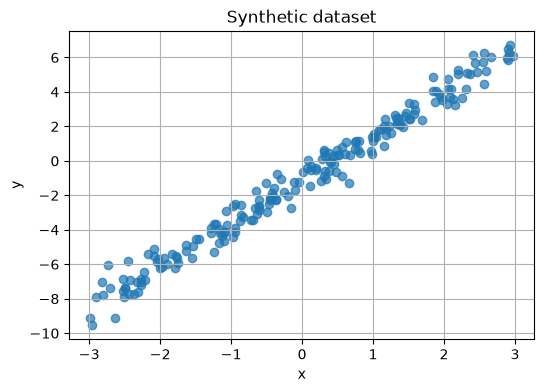

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

np.random.seed(123)
torch.manual_seed(123)

w_true = 2.5
b_true = -1.0
noise_std = 0.6 

n = 200

x = np.random.uniform(-3, 3, 200)

noise = np.random.normal(0, noise_std, n)

y = w_true*x + b_true+ noise

x_t = torch.tensor(x, dtype=torch.float32).view(-1,1)
y_t = torch.tensor(y, dtype=torch.float32).view(-1,1)

def plot_dataset(x_t, y_t):

    plt.figure(figsize=(6, 4))
    plt.scatter(x, y, alpha=0.7)
    
    plt.xlabel("x")
    plt.ylabel("y")
    plt.title("Synthetic dataset")
    plt.grid(True)
    plt.show()

plot_dataset(x_t, y_t)




## 2. Try various values for (w, b)

Before we train a model automatically, let’s build intuition by testing a few candidate lines.

We will compute predictions with hand-picked parameters $(w, b)$ and compare them against the data.

**What to do**

1. Define a list of candidate parameter pairs $(w, b)$. For example:  
   - (0.5, -2.0)  
   - (2.5, -1.0)  
   - (3.5, -1.0)  
   - (2.5, 1.0)  

2. For each candidate pair:  
   - Compute the predictions $\hat{y}$.  
   - Compute the mean squared error (MSE) between $y$ and $\hat{y}$.  

3. Plot:  
   - A scatter plot of the dataset (points).  
   - Each candidate line over the same range of $x$.  
   - Include the MSE of each line in the legend.  

In [2]:
candidates = [(0.5, -2.0), (2.5, -1.0), (3.5, -1.0), (2.5, 1.0)]

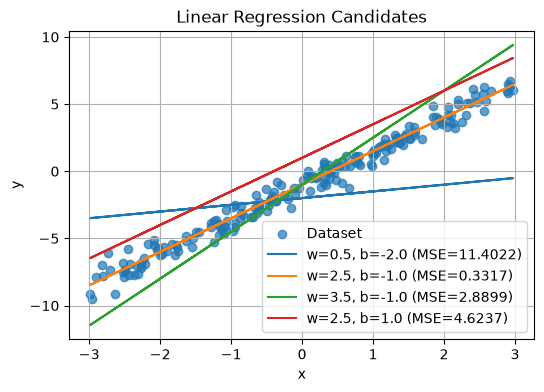

In [3]:
def compute_pred(x_t, y_t, w, b):
    y_hat = x_t * w + b
    return y_hat
    
def compute_MSE(y_t, y_hat):
    mse = ((y_t - y_hat)**2).mean()
    return mse

def plot(x_t, y_t, candidates):
    plt.figure(figsize=(6, 4))

    # Dataset
    plt.scatter(x_t, y_t, alpha=0.7, label="Dataset")

    # Candidate lines
    for w, b in candidates:
        y_hat = compute_pred(x_t, y_t, w, b)
        mse = compute_MSE(y_t, y_hat)

        plt.plot(
            x_t,
            y_hat,
            label=f"w={w}, b={b} (MSE={mse:.4f})"
        )

    plt.xlabel("x")
    plt.ylabel("y")
    plt.title("Linear Regression Candidates")
    plt.legend()
    plt.grid(True)
    plt.show()


plot(x_t, y_t, candidates)
    


## 3. Analytic solution

So far, we tried parameters $(w, b)$ by hand. Now, let’s compute the optimal solution for linear regression analytically.

We do this using the normal equations

$$
\tilde{w}^* = \left(\tilde{X}^\top \tilde{X}\right)^{-1} \tilde{X}^\top y
$$

where:
- $\tilde{X}$ is the augmented design matrix with a column of ones for the bias:  
  $$
  \tilde{X} =
  \begin{bmatrix}
  1 & x^{(1)} \
  1 & x^{(2)} \
  \vdots & \vdots \
  1 & x^{(n)}
  \end{bmatrix} \in \mathbb{R}^{n \times 2}
  $$
- $\tilde{w} = \begin{bmatrix} b \ w \end{bmatrix}$ contains both bias and slope.


**What to do**

1. Build the augmented design matrix $\tilde{X}$ by concatenating a column of ones with your vector $x$.  
2. Compute the closed-form solution $\tilde{w}^* = (\tilde{X}^\top \tilde{X})^{-1} \tilde{X}^\top y$ using PyTorch matrix operations (see [`torch.linalg.pinv`](https://docs.pytorch.org/docs/stable/generated/torch.linalg.pinv.html)).  
3. Extract the parameters $b$ (intercept) and $w$ (slope) from the solution.  
4. Compute the MSE between the predictions from the closed-form solution and the true $y$.  
5. Plot the data and overlay the fitted line corresponding to the closed-form solution.  


In [4]:
ones = torch.ones((200,1))

X_hat = torch.hstack((ones, x_t))

X_hat.shape

torch.Size([200, 2])

tensor([[-1.0730],
        [ 2.4975]])
tensor([-1.0730])
tensor([2.4975])


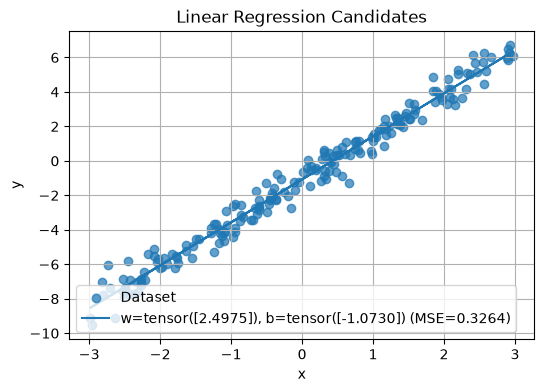

In [5]:
w_hat = torch.linalg.pinv(X_hat.T @ X_hat) @X_hat.T @ y_t
print(w_hat)
b, w = w_hat

print(b)
print(w)

candidate = [[w, b]]
plot(x_t, y_t, candidate)


In [6]:
w_optimal = w
b_optimal = b
loss_optimal = 0.3264

## 4. Training loop 

We will now train linear regression using PyTorch’s autograd as seen in the slides.  
You will implement the classic loop: forward → loss → backward → update → zero grads.

**Setup**

- Use your tensors from Step 1: `x`, `y` (dtype `float32`).  
- Initialize parameters as tensors with gradients.
- Keep predictions and targets the same shape to avoid unintended broadcasting.
- Learning rate `lr = 1e-2`  
- Number of epochs `epochs = 200` (increase if needed)


**What to do**

1. Implement the training loop
2. After training, report the learned parameters `w` and `b` (detach from the graph), and the final loss.
3. Try change the code so that the parameters (`w` and `b`) are updated without requiring `with torch.no_grad()`.



In [7]:
def train(x_t, y_t, lr, epochs):
    loss_history = []
    
    w = torch.zeros((x_t.shape[1],1), requires_grad=True)
    b = torch.zeros(1, requires_grad=True)

    for epoch in range(epochs):
        y_hat = x_t @ w + b
    
        loss = ((y_t - y_hat)**2).mean()
    
        loss_history.append(loss.detach().clone())
    
        loss.backward()
    
        w.data -= lr * w.grad
        b.data -= lr * b.grad
            
        w.grad.zero_()
        b.grad.zero_()
    
    w_learn = w.detach().clone()
    b_learn = b.detach().clone()

    return w_learn, b_learn, loss_history

x_t = torch.tensor(x, dtype=torch.float32).view(-1,1)
y_t = torch.tensor(y, dtype=torch.float32).view(-1,1)

lr = 1e-2
epochs = 200

w_learn, b_learn, loss_history = train(x_t, y_t, lr, epochs)

## 5. Track the loss and plot convergence

A common practice when learning a model with GS or a similar algorithm is to track the training loss over epochs to visualize convergence.

**What to do**

1. Record the MSE at each epoch during training (you can use a Python list `loss_history` with one scalar per epoch).
2. Plot **loss vs. epoch** to see how gradient descent behaves.



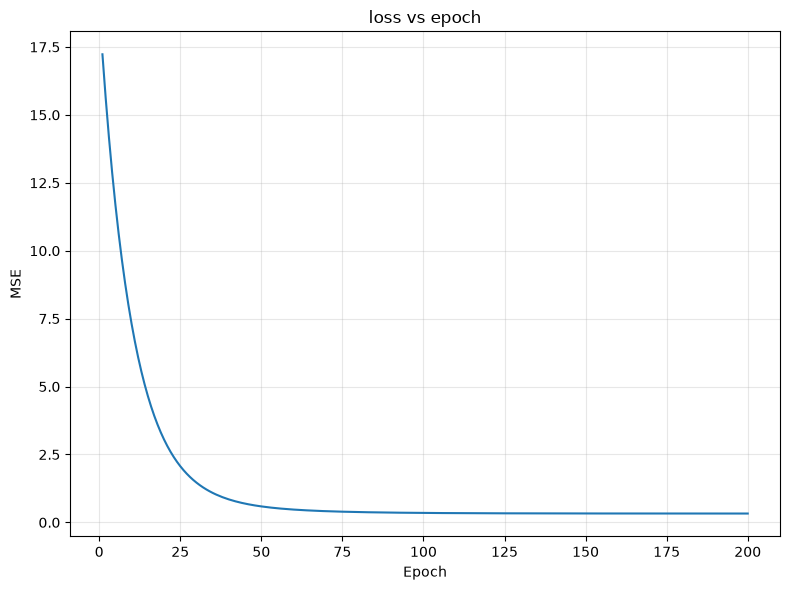

In [8]:
def plot_loss_history(loss_history, plt, label=None):
    
    plt.plot(range(1, len(loss_history) + 1),loss_history,label=label)
    #final_loss = loss_history[-1]
    plt.xlabel("Epoch")
    plt.ylabel("MSE")
    plt.title("loss vs epoch")
    plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    

plt.figure(figsize=(8, 6))

plot_loss_history(loss_history, plt)
plt.show()


## 6. Visualize the fitted model

Now that you have trained the model and logged convergence, let’s inspect the final fit visually.

**What to do**

- Use your learned parameters `(w_learn, b_learn)` to draw the regression line on top of the data.
- Check visually that the line matches the trend in the scatter.


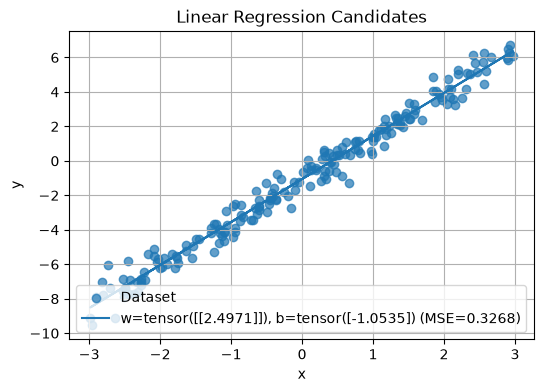

In [9]:
candidate = [[w_learn, b_learn]]
plot(x_t, y_t, candidate)

## 7. Compare convergence for multiple `lr` values

We will investigate how the learning rate (`lr`) affects convergence speed and stability when training with gradient descent.

**What to do**

- Train the same model multiple times with different `lr` values.
- Log and plot the loss curves together to compare convergence behavior.
- Identify ranges that are too small (slow), good (fast & stable), and too large (oscillation/divergence).




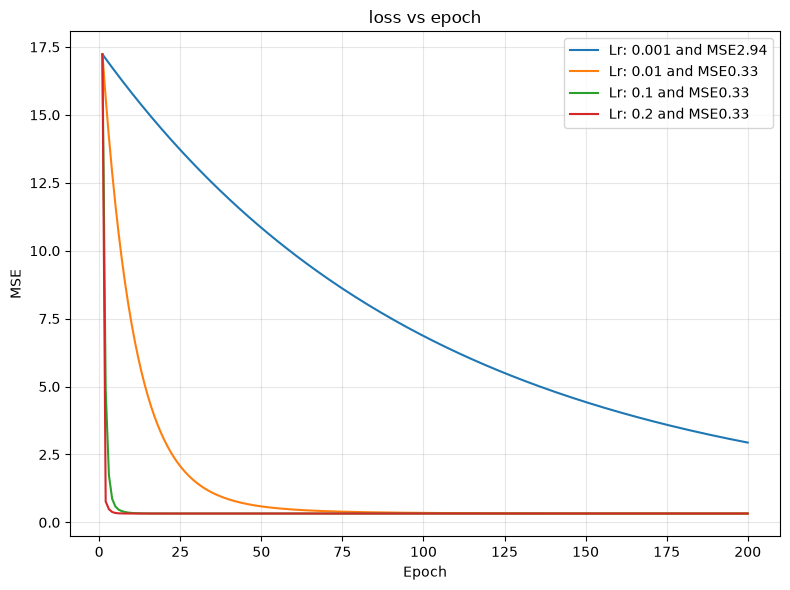

In [10]:
lr_values = [1e-3,1e-2, 0.1, 0.2]

x_t = torch.tensor(x, dtype=torch.float32).view(-1,1)
y_t = torch.tensor(y, dtype=torch.float32).view(-1,1)

plt.figure(figsize=(8, 6))
for lr in lr_values:
    w_learn, b_learn, loss_history = train(x_t, y_t, lr, epochs)
    plot_loss_history(loss_history, plt, f'Lr: {lr} and MSE{loss_history[-1]:.2f}')
    #candidate = [[w_learn, b_learn]]
    #plot(x_t, y_t, candidate)
plt.legend()
plt.show()


## 8. Train/Validation split

We have only trained and evaluated on the same dataset, but, to better understand generalization, we will split our data into training and validation sets and monitor both losses during training.

**What to do**

- Create a train/validation split of the dataset (Use ~75% of the data for training, ~25% for validation). This can be done shuffling indices and making a manual partition.
- Train only on the training set.  
- At each epoch, compute both training loss and validation loss.  
- Plot both curves together to compare behaviors.


In [11]:
x_t = torch.tensor(x, dtype=torch.float32).view(-1, 1)
y_t = torch.tensor(y, dtype=torch.float32).view(-1, 1)

# Índices aleatorios
indices = torch.randperm(len(x_t))

# 75% train, 25% validation
split = int(0.75 * len(x_t))

train_indices = indices[:split]
val_indices = indices[split:]

# Crear datasets
x_train = x_t[train_indices]
y_train = y_t[train_indices]

x_val = x_t[val_indices]
y_val = y_t[val_indices]


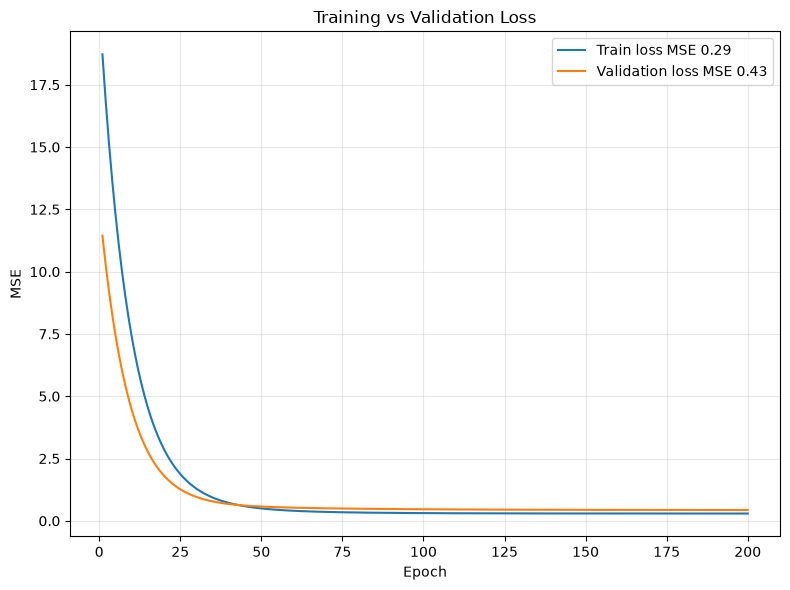

In [12]:
def train_pro(x_train, y_train, x_val, y_val, lr, epochs):
    train_loss_history = []
    val_loss_history = []

    w = torch.zeros((x_train.shape[1], 1), requires_grad=True)
    b = torch.zeros(1, requires_grad=True)

    for epoch in range(epochs):
        # Forward pass SOLO con training
        y_hat = x_train @ w + b

        # Training loss
        train_loss = ((y_train - y_hat) ** 2).mean()

        # Guardamos training loss
        train_loss_history.append(train_loss.detach().clone())

        # Backpropagation
        train_loss.backward()

        # Actualizamos parámetros
        w.data -= lr * w.grad
        b.data -= lr * b.grad

        # Reiniciamos gradientes
        w.grad.zero_()
        b.grad.zero_()

        # Validation loss --> no haces el backward
        y_hat_val = x_val @ w + b
        val_loss = ((y_val - y_hat_val) ** 2).mean()

        val_loss_history.append(val_loss.detach().clone())

    w_learn = w.detach().clone()
    b_learn = b.detach().clone()

    return w_learn, b_learn, train_loss_history, val_loss_history

lr = 1e-2
epochs = 200

w_learn, b_learn, train_loss_history, val_loss_history = train_pro(x_train,y_train,x_val,y_val,lr,epochs)

plt.figure(figsize=(8, 6))

plot_loss_history(train_loss_history, plt, f'Train loss MSE {train_loss_history[-1]:.2f}')
plot_loss_history(val_loss_history, plt,  f'Validation loss MSE {val_loss_history[-1]:.2f}')

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Training vs Validation Loss")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [13]:
w_mse = w_learn
b_mse = b_learn

## 9. Visualize the loss surface

Linear regression with one feature has only two parameters: $w$ (slope) and $b$ (intercept).  
This makes it possible to visualize the entire loss surface $\mathcal{L}(w,b)$.

**What to do**

1. Define a grid of parameter values:
   - Create a range of values for $w$ (e.g., from -5 to +5).  
   - Create a range of values for $b$ (e.g., from -5 to +5).  
   - Use `torch.meshgrid` or `np.meshgrid` to form all $(w, b)$ pairs.

2. For each $(w, b)$ pair:
   - Compute predictions $\hat{y}$.  
   - Compute the MSE over the dataset.  
   - Store results in a 2D array matching the grid.

3. Plot the loss surface in two ways:
   - 3D surface plot of $\mathcal{L}(w,b)$ (you can use [`plot_surface`](https://matplotlib.org/stable/plot_types/3D/surface3d_simple.html)).
   - Contour plot (2D view with level curves) (you can use [`contour`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.contour.html)).

4. Highlight the minimum point (from the analytic solution from Step 2b) on the plots.



In [14]:
x_t = torch.tensor(x, dtype=torch.float32).view(-1,1)
y_t = torch.tensor(y, dtype=torch.float32).view(-1,1)

w_values = torch.linspace(-5, 5, 100)
b_values = torch.linspace(-5, 5, 100)

grid_w, grid_b = torch.meshgrid(w_values, b_values, indexing='ij')

loss_surface = torch.zeros_like(grid_w)

for i, (w, b) in enumerate(zip(grid_w.flatten(), grid_b.flatten())):
    y_hat = x_t * w + b
    mse = ((y_t - y_hat) ** 2).mean()

    loss_surface.flatten()[i] = mse

In [15]:
w_optimal
b_optimal
loss_optimal

0.3264

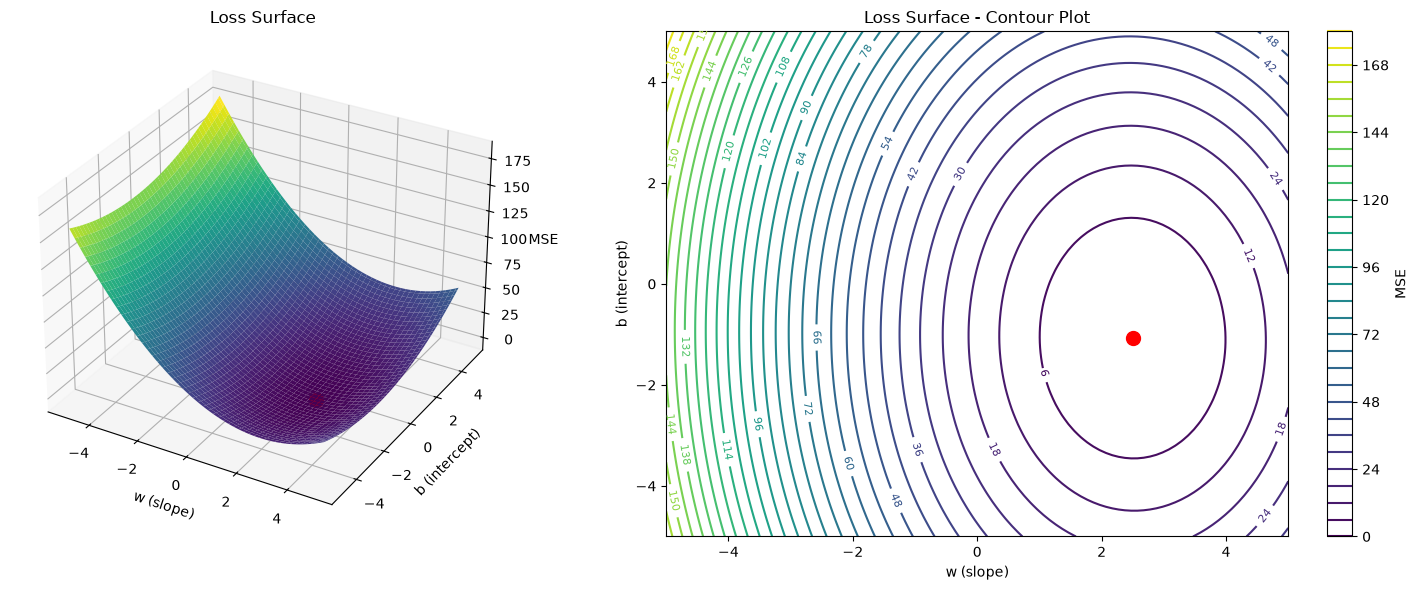

In [16]:
fig = plt.figure(figsize=(16, 6))

# -------------------------
# 3D Surface
# -------------------------
ax1 = fig.add_subplot(1, 2, 1, projection='3d')

ax1.plot_surface(grid_w.numpy(),grid_b.numpy(),loss_surface.detach().numpy(),cmap='viridis')

ax1.set_xlabel('w (slope)')
ax1.set_ylabel('b (intercept)')
ax1.set_zlabel('MSE')
ax1.set_title('Loss Surface')
ax1.scatter(
    w_optimal.item(),
    b_optimal.item(),
    loss_optimal,
    color='red',
    s=100,
    label='Optimal'
)


# -------------------------
# Contour plot
# -------------------------
ax2 = fig.add_subplot(1, 2, 2)

contour = ax2.contour(grid_w.numpy(),grid_b.numpy(),loss_surface.detach().numpy(),levels=30,cmap='viridis')
ax2.clabel(contour, inline=True, fontsize=8)
ax2.set_xlabel('w (slope)')
ax2.set_ylabel('b (intercept)')
ax2.set_title('Loss Surface - Contour Plot')
ax2.scatter(
    w_optimal.item(),
    b_optimal.item(),
    color='red',
    s=100,
    label='Optimal'
)

fig.colorbar(contour, ax=ax2, label='MSE')

noise_std = 0.6 

n = 200

x = np.random.uniform(-3, 3, 200)

noise = np.random.normal(0, noise_std, n)
# Ajustar espacios
plt.tight_layout()

plt.show()


## 10. Gradient descent path on the loss surface

Now that you have plotted the loss surface $\mathcal{L}(w, b)$, let’s overlay the actual path taken by gradient descent.  
This will help you see how the optimizer moves through parameter space. The idea is to track $(w, b)$ values at each epoch during training and overlay this trajectory on the contour plot and 3D surface plot of the loss. There is also a visible relation between this path and the loss vs. epoch curve. 

**What to do**

1. Modify your training loop from Step 3 so that it also:
   - Stores the current values of $w$ and $b$ at each epoch.  
   - Stores the corresponding loss.  

2. Train for ~200 epochs from an initial guess (e.g., `w0 = -3.0`, `b0 = 3.0`).  

3. Plot three visuals:
   - Contour plot of the loss surface with the GD path drawn on top.  
     - Mark the start point (different color) and end point.  
   - 3D surface plot with the GD path as a red line.  
   - Loss vs. epoch curve to connect movement in parameter space with decrease in loss.  



In [17]:
def train(x_t, y_t, lr, epochs, w0=-3.0, b0=3.0):
    loss_history = []
    w_history = []
    b_history = []
    
    # Initial values
    w = torch.tensor([[w0]], dtype=torch.float32, requires_grad=True)
    b = torch.tensor([b0], dtype=torch.float32, requires_grad=True)

    for epoch in range(epochs):
        
        # Forward pass
        y_hat = x_t @ w + b
    
        # Loss
        loss = ((y_t - y_hat)**2).mean()
    
        # Store current values
        loss_history.append(loss.detach().item())
        w_history.append(w.detach().item())
        b_history.append(b.detach().item())
    
        # Backpropagation
        loss.backward()
    
        # Gradient descent update
        with torch.no_grad():
            w -= lr * w.grad
            b -= lr * b.grad
            
        # Reset gradients
        w.grad.zero_()
        b.grad.zero_()
    
    # Final parameters
    w_learn = w.detach().clone()
    b_learn = b.detach().clone()

    return w_learn, b_learn, loss_history, w_history, b_history


In [18]:
x_t = torch.tensor(x, dtype=torch.float32).view(-1, 1)
y_t = torch.tensor(y, dtype=torch.float32).view(-1, 1)

lr = 1e-2
epochs = 200

w_learn, b_learn, loss_history, w_history, b_history = train(x_t,y_t,lr,epochs,w0=-3.0,b0=3.0)


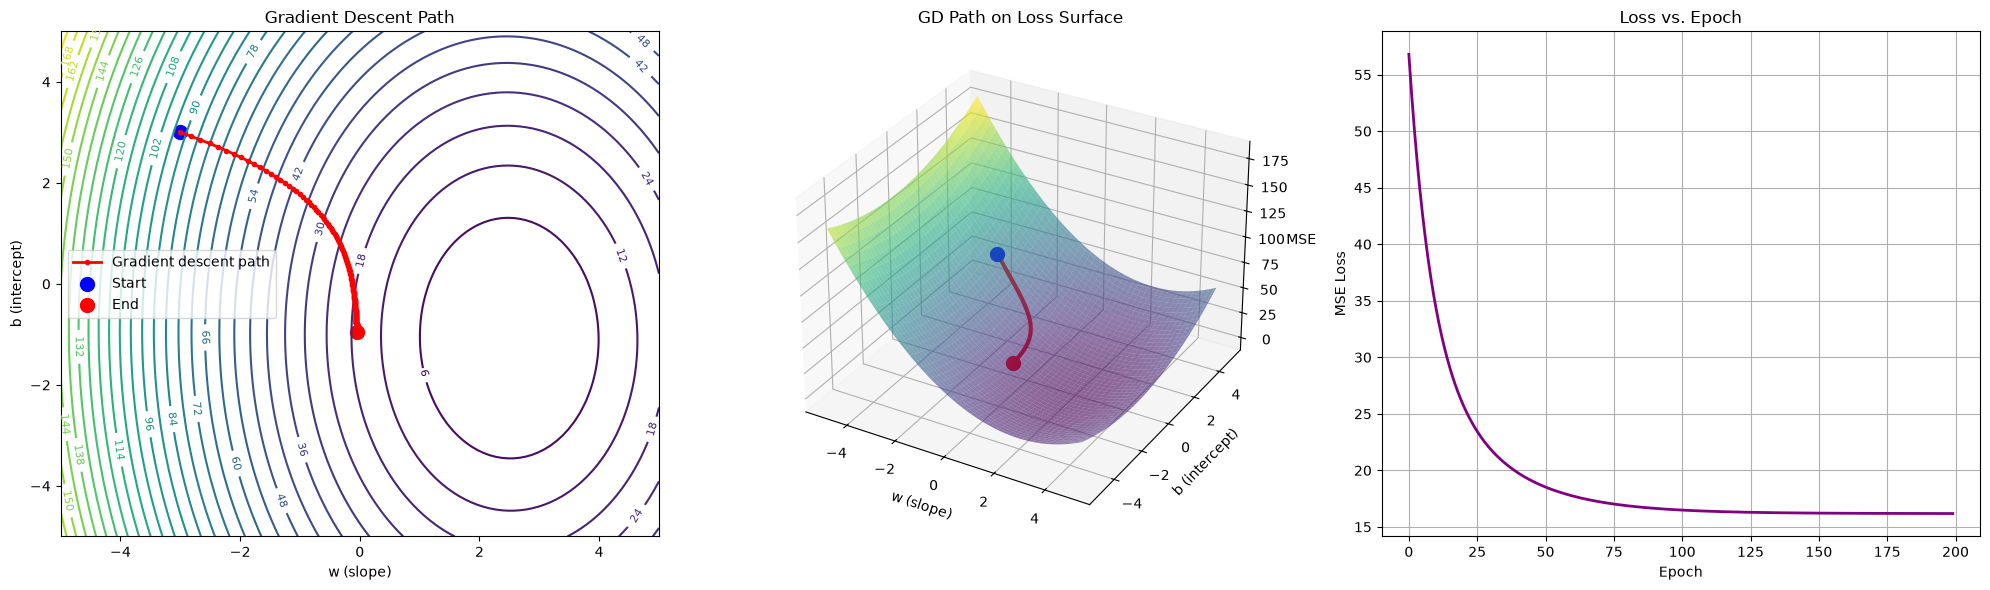

In [19]:
fig = plt.figure(figsize=(20, 6))

# ==================================================
# 1. Contour plot + GD path
# ==================================================
ax1 = fig.add_subplot(1, 3, 1)

contour = ax1.contour(grid_w.numpy(),grid_b.numpy(),loss_surface.numpy(),levels=30,cmap='viridis')

ax1.clabel(contour,inline=True,fontsize=8)

# Gradient descent path
ax1.plot(w_history,b_history,color='red',linewidth=2,marker='o',markersize=3,label='Gradient descent path')

# Starting point
ax1.scatter(w_history[0],b_history[0],color='blue',s=100,label='Start')

# Final point
ax1.scatter(w_history[-1],b_history[-1],color='red',s=100,label='End')

ax1.set_xlabel('w (slope)')
ax1.set_ylabel('b (intercept)')
ax1.set_title('Gradient Descent Path')
ax1.legend()


# ==================================================
# 2. 3D surface + GD path
# ==================================================
ax2 = fig.add_subplot(1, 3, 2, projection='3d')

# Loss surface
ax2.plot_surface(grid_w.numpy(),grid_b.numpy(),loss_surface.numpy(),cmap='viridis',alpha=0.6)

# Gradient descent path
ax2.plot(w_history,b_history,loss_history,color='red',linewidth=3,label='Gradient descent path')

# Starting point
ax2.scatter(w_history[0],b_history[0],loss_history[0],color='blue',s=100)

# Final point
ax2.scatter(w_history[-1],b_history[-1],loss_history[-1],color='red',s=100)

ax2.set_xlabel('w (slope)')
ax2.set_ylabel('b (intercept)')
ax2.set_zlabel('MSE')
ax2.set_title('GD Path on Loss Surface')


# ==================================================
# 3. Loss vs Epoch
# ==================================================
ax3 = fig.add_subplot(1, 3, 3)

ax3.plot(range(epochs),loss_history,color='purple',linewidth=2)

ax3.set_xlabel('Epoch')
ax3.set_ylabel('MSE Loss')
ax3.set_title('Loss vs. Epoch')
ax3.grid(True)


# ==================================================
# Layout
# ==================================================
plt.tight_layout()
plt.show()

## 11. Create a new multivariate dataset (d > 1)

So far we only used one feature. Now let’s extend to a dataset with multiple features to see how gradient descent behaves in higher dimensions and why feature scaling is important.

**What to do**

1. Generate the dataset
   - Number of samples: `n = 600`.  
   - Number of features: choose `d = 6`.  
   - Sample standard normal features with `torch.randn`.  
   - Multiply each feature by a different scale (e.g., 1, 100, 0.01, 50, 10, 0.1).  
   - Define ground-truth parameters `w_true` (values `[2.0, -3.5, 0.5, 10.0, -0.2, 0.05]`) and `b_true` (value `4.0`).  
   - Generate `y = X @ w_true + b_true + noise`.

2. Split into train and validation sets
   - Use ~80% for training, 20% for validation (shuffle indices with `torch.randperm`).

3. Train with unscaled features
   - Extend your training loop to handle multiple features. 
   - Log both training and validation losses per epoch.  
   - Plot the curves.

4. Apply feature scaling
   - Compute mean and standard deviation of each column on the training set.  
   - Standardize both train and validation features. 
   - Retrain with the same loop, same hyperparameters.  
   - Plot the new loss curves.

5. Compare
   - Plot unscaled vs. scaled convergence curves in one figure.  
   - Compare learned parameters to the true ones (for the scaled case, map back to the original scale).


In [20]:
n = 6000
d = 6
noise_std = 0.6

dataset = torch.rand(n, d)

scales = torch.tensor([1, 100, 0.01, 50, 10, 0.1])

X = dataset * scales.reshape(1, -1)

w_true = torch.tensor([2.0, -3.5, 0.5, 10.0, -0.2, 0.05],dtype=torch.float32)
b_true = 4.0

noise = torch.tensor(np.random.normal(0, noise_std, n),dtype=torch.float32)

y = X @ w_true + b_true + noise

In [21]:
indices = torch.randperm(n)

n_train = int(0.8 * n)
print(n_train)
train_idx = indices[:n_train]
val_idx = indices[n_train:]

x_train = X[train_idx]
y_train = y[train_idx]

x_val = X[val_idx]
y_val = y[val_idx]

print(x_train.shape)
print(y_train.shape)
print(x_val.shape)
print(y_val.shape)

4800
torch.Size([4800, 6])
torch.Size([4800])
torch.Size([1200, 6])
torch.Size([1200])


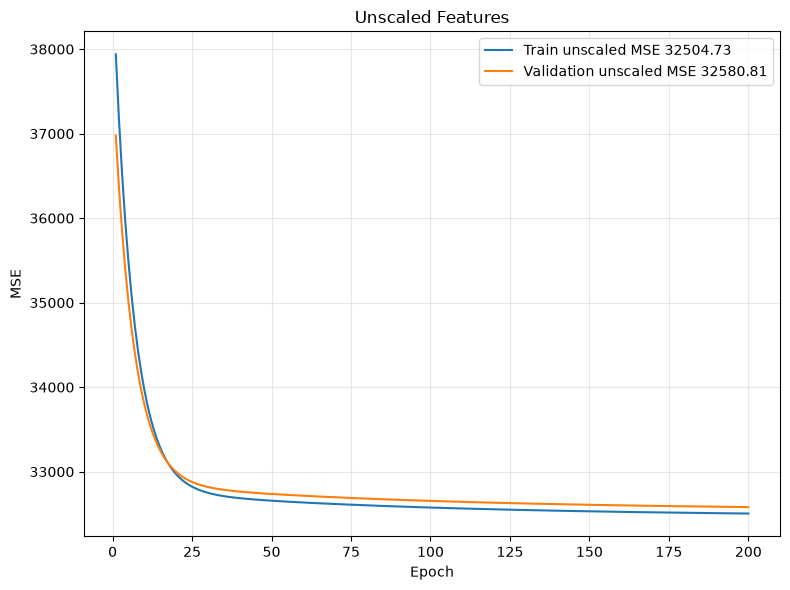

In [22]:
lr = 1e-5
epochs = 200

w_unscaled, b_unscaled, train_loss_unscaled, val_loss_unscaled = train_pro(x_train,y_train,x_val,y_val,lr,epochs)

plt.figure(figsize=(8, 6))

plot_loss_history(
    train_loss_unscaled,
    plt,
    f'Train unscaled MSE {train_loss_unscaled[-1]:.2f}'
)

plot_loss_history(
    val_loss_unscaled,
    plt,
    f'Validation unscaled MSE {val_loss_unscaled[-1]:.2f}'
)

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Unscaled Features")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [23]:
mean_train = x_train.mean(dim=0)
std_train = x_train.std(dim=0)

x_train_scaled = (x_train - mean_train) / std_train
x_val_scaled = (x_val - mean_train) / std_train

print("Mean:", x_train_scaled.mean(dim=0))
print("Std:", x_train_scaled.std(dim=0))

Mean: tensor([-3.5763e-08,  1.3908e-08, -1.2358e-07, -8.7818e-08, -7.5499e-08,
        -1.3431e-07])
Std: tensor([1., 1., 1., 1., 1., 1.])


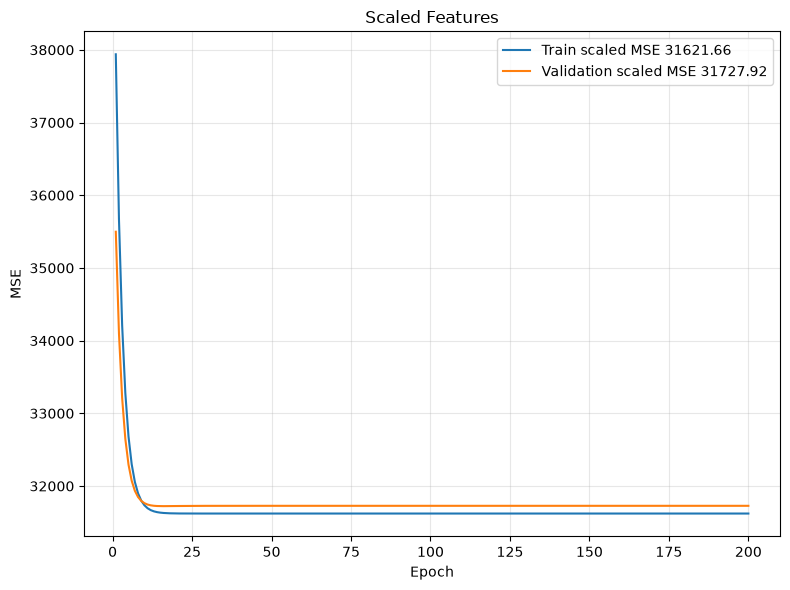

In [24]:
lr = 1e-1
epochs = 200

w_scaled, b_scaled, train_loss_scaled, val_loss_scaled = train_pro(x_train_scaled,y_train,x_val_scaled,y_val,lr,epochs)

plt.figure(figsize=(8, 6))

plot_loss_history(
    train_loss_scaled,
    plt,
    f'Train scaled MSE {train_loss_scaled[-1]:.2f}'
)

plot_loss_history(
    val_loss_scaled,
    plt,
    f'Validation scaled MSE {val_loss_scaled[-1]:.2f}'
)

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Scaled Features")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

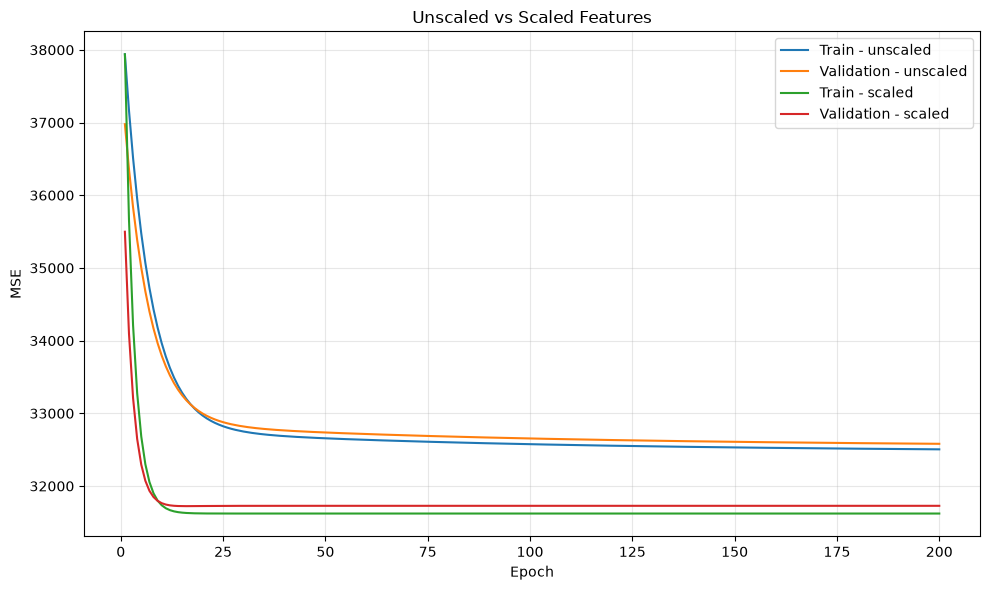

In [25]:
plt.figure(figsize=(10, 6))

plot_loss_history(
    train_loss_unscaled,
    plt,
    "Train - unscaled"
)

plot_loss_history(
    val_loss_unscaled,
    plt,
    "Validation - unscaled"
)

plot_loss_history(
    train_loss_scaled,
    plt,
    "Train - scaled"
)

plot_loss_history(
    val_loss_scaled,
    plt,
    "Validation - scaled"
)

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Unscaled vs Scaled Features")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [26]:
w_scaled_original = w_scaled / std_train.reshape(-1, 1)

b_scaled_original = (b_scaled- (mean_train.reshape(1, -1) @ w_scaled_original).squeeze())

print("True weights:")
print(w_true)

print("\nLearned weights:")
print(w_scaled_original.squeeze())

print("\nTrue bias:")
print(b_true)

print("\nLearned bias:")
print(b_scaled_original)

True weights:
tensor([ 2.0000, -3.5000,  0.5000, 10.0000, -0.2000,  0.0500])

Learned weights:
tensor([-4.4078e-07,  3.2335e-09, -2.7540e-04, -3.1816e-08, -1.2248e-07,
        -3.0576e-05])

True bias:
4.0

Learned bias:
tensor([79.4812])


## 12. Training with MAE

So far, we have always used the Mean Squared Error (MSE). Now let’s try the Mean Absolute Error (MAE) loss:

$$
\mathcal{L}_{\text{MAE}} = \frac{1}{n} \sum_{i=1}^n \left| y^{(i)} - \hat{y}^{(i)} \right|
$$


**What to do**

1. Copy your training loop from the MSE case.  
2. Change the loss definition to absolute error instead of squared error.  
3. Train the model on the same dataset (you can use the 1D dataset for simplicity).  
4. Log the loss over epochs and plot the convergence curve.  
5. Compare the fitted line from MAE to the fitted line from MSE.

In [27]:
def train_pro_mae(x_train, y_train, x_val, y_val, lr, epochs):
    train_loss_history = []
    val_loss_history = []

    w = torch.zeros((x_train.shape[1], 1), requires_grad=True)
    b = torch.zeros(1, requires_grad=True)

    for epoch in range(epochs):

        # Forward pass
        y_hat = x_train @ w + b

        # MAE loss
        train_loss = torch.abs(y_train - y_hat).mean()

        # Guardamos training loss
        train_loss_history.append(train_loss.detach().clone())

        # Backpropagation
        train_loss.backward()

        # Actualizamos parámetros
        w.data -= lr * w.grad
        b.data -= lr * b.grad

        # Reiniciamos gradientes
        w.grad.zero_()
        b.grad.zero_()

        # Validation loss
        y_hat_val = x_val @ w + b
        val_loss = torch.abs(y_val - y_hat_val).mean()

        val_loss_history.append(val_loss.detach().clone())

    w_learn = w.detach().clone()
    b_learn = b.detach().clone()
    return w_learn, b_learn, train_loss_history, val_loss_history

w MAE: 2.4727039337158203
b MAE: -0.9362503290176392


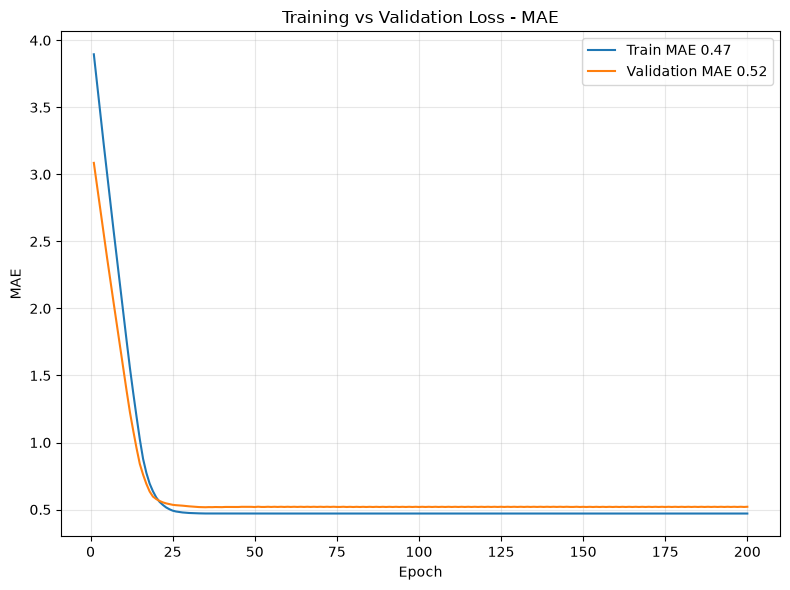

In [28]:
w_true = 2.5
b_true = -1.0
noise_std = 0.6 

n = 200

x = np.random.uniform(-3, 3, 200)

noise = np.random.normal(0, noise_std, n)

y = w_true*x + b_true+ noise

x_t = torch.tensor(x, dtype=torch.float32).view(-1,1)
y_t = torch.tensor(y, dtype=torch.float32).view(-1,1)


# Shuffle indices
indices = torch.randperm(n)

n_train = int(0.8 * n)

train_idx = indices[:n_train]
val_idx = indices[n_train:]

x_train = x_t[train_idx]
y_train = y_t[train_idx]

x_val = x_t[val_idx]
y_val = y_t[val_idx]


lr = 1e-1
epochs = 200

w_mae, b_mae, train_loss_mae, val_loss_mae = train_pro_mae(
    x_train,
    y_train,
    x_val,
    y_val,
    lr,
    epochs
)

print("w MAE:", w_mae.item())
print("b MAE:", b_mae.item())

plt.figure(figsize=(8, 6))

plot_loss_history(
    train_loss_mae,
    plt,
    f"Train MAE {train_loss_mae[-1].item():.2f}"
)

plot_loss_history(
    val_loss_mae,
    plt,
    f"Validation MAE {val_loss_mae[-1].item():.2f}"
)

plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.title("Training vs Validation Loss - MAE")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [29]:
x_plot = torch.linspace(
    x_t.min(),
    x_t.max(),
    200
).reshape(-1, 1)

y_pred_mse = x_plot @ w_mse + b_mse
y_pred_mae = x_plot @ w_mae + b_mae

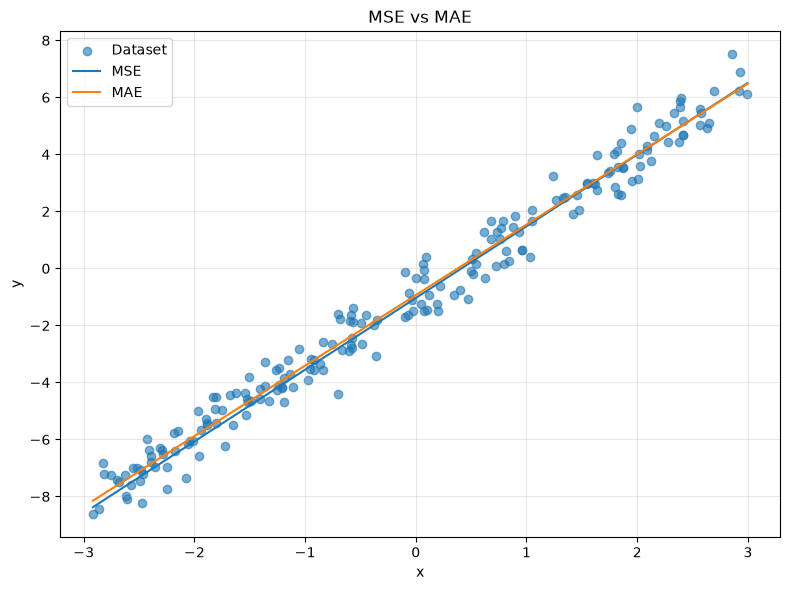

In [30]:
plt.figure(figsize=(8, 6))

plt.scatter(
    x_t.numpy(),
    y_t.numpy(),
    alpha=0.6,
    label="Dataset"
)

plt.plot(
    x_plot.numpy(),
    y_pred_mse.detach().numpy(),
    label="MSE"
)

plt.plot(
    x_plot.numpy(),
    y_pred_mae.detach().numpy(),
    label="MAE"
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("MSE vs MAE")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 13. Outlier sensitivity (MSE vs MAE)

Let's compare the performance of MSE and MAE in a specific situation. While generally MSE is the standard loss for linear regression, it is  sensitive to outliers, because squaring residuals amplifies large errors.  MAE is more robust, since it grows linearly with the error.

**What to do**

1. Take your original 1D dataset from Step 1.  
2. Add a few outlier points far from the linear trend: large $x$ values (e.g., 5.0, 5.5 and 6.0) with very large $y$ (e.g., 20.0, 22.0 and 24.0).  
3. Retrain two models on this augmented dataset:
   - One with MSE loss.  
   - One with MAE loss.  
4. Plot:
   - The original data (including outliers).  
   - The fitted line from the MSE model.  
   - The fitted line from the MAE model.  
   - Use a legend to distinguish them.


In [31]:
x_outliers = torch.tensor([[5.0], [5.5], [6.0]])
y_outliers = torch.tensor([[20.0], [22.0], [24.0]])

# Dataset aumentado
x_aug = torch.cat([x_t, x_outliers], dim=0)
y_aug = torch.cat([y_t, y_outliers], dim=0)

print(x_aug.shape)
print(y_aug.shape)

torch.Size([203, 1])
torch.Size([203, 1])


In [32]:
lr = 1e-1
epochs = 500

# MSE
w_mse_out, b_mse_out, _, _ = train_pro(
    x_aug,
    y_aug,
    x_aug,
    y_aug,
    lr,
    epochs
)

# MAE
w_mae_out, b_mae_out, _, _ = train_pro_mae(
    x_aug,
    y_aug,
    x_aug,
    y_aug,
    lr,
    epochs
)

print("MSE:")
print("w =", w_mse_out.item())
print("b =", b_mse_out.item())

print("\nMAE:")
print("w =", w_mae_out.item())
print("b =", b_mae_out.item())

MSE:
w = 2.707132339477539
b = -0.7957342267036438

MAE:
w = 2.471860885620117
b = -0.9359609484672546


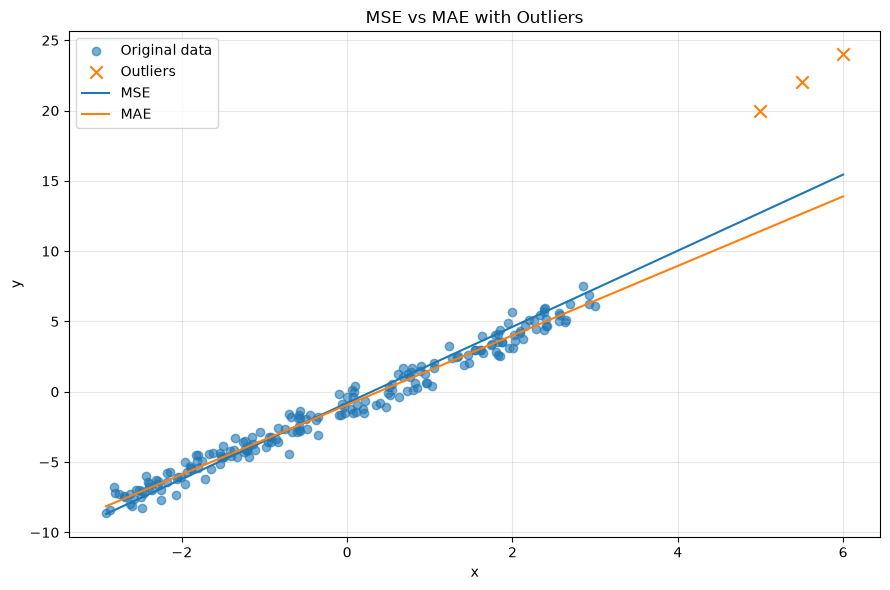

In [33]:
x_plot = torch.linspace(
    x_aug.min(),
    x_aug.max(),
    200
).reshape(-1, 1)

y_pred_mse = x_plot @ w_mse_out + b_mse_out
y_pred_mae = x_plot @ w_mae_out + b_mae_out

plt.figure(figsize=(9, 6))

# Datos originales
plt.scatter(
    x_t.numpy(),
    y_t.numpy(),
    alpha=0.6,
    label="Original data"
)

# Outliers
plt.scatter(
    x_outliers.numpy(),
    y_outliers.numpy(),
    marker="x",
    s=80,
    label="Outliers"
)

# MSE
plt.plot(
    x_plot.numpy(),
    y_pred_mse.detach().numpy(),
    label="MSE"
)

# MAE
plt.plot(
    x_plot.numpy(),
    y_pred_mae.detach().numpy(),
    label="MAE"
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("MSE vs MAE with Outliers")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

MSE → más sensible a outliers

MAE → más robusto frente a outliers

## 14. From manual updates to PyTorch optimizers

Up to now, we implemented gradient descent by hand:
- Forward pass → compute loss  
- Backward pass → `loss.backward()`  
- Parameter update with `w -= lr * w.grad` and `b -= lr * b.grad` inside `with torch.no_grad()`  
- Gradient reset with `w.grad.zero_()` and `b.grad.zero_()`  

Now we will see how PyTorch provides optimizers that automate this part.

**What to do**

- Replace manual parameter updates with [`torch.optim.SGD`](https://docs.pytorch.org/docs/stable/generated/torch.optim.SGD.html).  
- Confirm that training works the same way.  


In [34]:
def train_pro_sgd(x_train, y_train, x_val, y_val, lr, epochs):
    train_loss_history = []
    val_loss_history = []

    w = torch.zeros((x_train.shape[1], 1), requires_grad=True)
    b = torch.zeros(1, requires_grad=True)

    # Crear el optimizador
    optimizer = torch.optim.SGD([w, b], lr=lr)

    for epoch in range(epochs):

        # Forward pass
        y_hat = x_train @ w + b

        # Training loss (MSE)
        train_loss = ((y_train - y_hat) ** 2).mean()

        # Guardamos loss
        train_loss_history.append(train_loss.detach().clone())

        # Backpropagation
        train_loss.backward()

        # Actualizamos parámetros
        optimizer.step()

        # Reiniciamos gradientes
        optimizer.zero_grad()

        # Validation
        y_hat_val = x_val @ w + b
        val_loss = ((y_val - y_hat_val) ** 2).mean()

        val_loss_history.append(val_loss.detach().clone())

    w_learn = w.detach().clone()
    b_learn = b.detach().clone()

    return w_learn, b_learn, train_loss_history, val_loss_history

w: 2.4838035106658936
b: -0.926363468170166


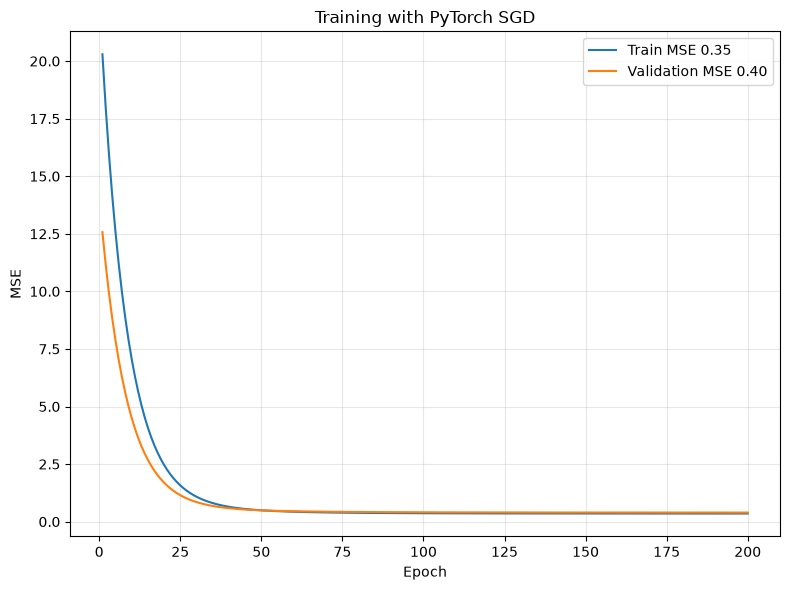

In [35]:
lr = 1e-2
epochs = 200

w_sgd, b_sgd, train_loss_sgd, val_loss_sgd = train_pro_sgd(
    x_train,
    y_train,
    x_val,
    y_val,
    lr,
    epochs
)

print("w:", w_sgd.item())
print("b:", b_sgd.item())

plt.figure(figsize=(8, 6))

plot_loss_history(
    train_loss_sgd,
    plt,
    f"Train MSE {train_loss_sgd[-1].item():.2f}"
)

plot_loss_history(
    val_loss_sgd,
    plt,
    f"Validation MSE {val_loss_sgd[-1].item():.2f}"
)

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Training with PyTorch SGD")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

| Antes, manual           | Con `SGD`               |
| ----------------------- | ----------------------- |
| `loss.backward()`       | `loss.backward()`       |
| `w.data -= lr * w.grad` | `optimizer.step()`      |
| `b.data -= lr * b.grad` | `optimizer.step()`      |
| `w.grad.zero_()`        | `optimizer.zero_grad()` |
| `b.grad.zero_()`        | `optimizer.zero_grad()` |
